# 05 — Modelo final e avaliação no teste

**Objetivo:** treinar o modelo escolhido no notebook 04 (LightGBM #11 com `scale_pos_weight = 1`) com todos os meses de treino (0–5) e avaliá-lo **uma única vez** no conjunto de teste (meses 6–7), nunca usado até aqui. Depois: política de limiar, justiça por idade, interpretação (SHAP) e o modelo salvo.

> **Regra:** o teste mede, não decide. Nenhuma escolha de modelo ou hiperparâmetro é revista com base nele.

### O que esperamos (escrito antes de abrir o teste)

1. **Recall a 5% de FPR menor que na validação.** O 0,5665 do LightGBM é o melhor de 30 candidatos (viés de seleção), e o desempenho caiu fold a fold em todos os modelos (drift). Esperamos algo entre ~0,50 e ~0,55.
2. **A vantagem sobre a regressão logística se mantém** (~+0,03 de recall), por ter sido consistente nos 3 folds.
3. **PR-AUC maior que na validação**, mas **sem significar um modelo melhor**: a taxa de fraude no teste é ~1,4% (maior que no treino), e a PR-AUC sobe com ela.

In [4]:
import ast
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd

EM_COLAB = "google.colab" in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/fraude-abertura-conta")
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAIZ = Path(os.getenv("FRAUDE_RAIZ", RAIZ))
DATA_DIR = RAIZ / "data"
FIG_DIR = RAIZ / "reports" / "figures"

sys.path.insert(0, str(RAIZ))
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression

from src.experimentos import pontuar
from src.perfis import SEMENTE, pipeline_arvores, pipeline_escala
from src.preprocessamento import ALVO, limpar
from src.validacao import avaliar

treino = pd.read_parquet(DATA_DIR / "train.parquet")

# Hiperparâmetros do modelo final: lidos do resultado da busca (notebook 04), não digitados à mão
busca = pd.read_csv(RAIZ / "reports" / "busca_04_modelos.csv")
PARAMS_FINAIS = ast.literal_eval(busca.loc[busca["id"] == "lightgbm #11", "params"].iloc[0])
PARAMS_FINAIS["scale_pos_weight"] = 1  # decisão da seção 6 do notebook 04
UNDERSAMPLING = PARAMS_FINAIS.pop("undersampling")
print("Hiperparâmetros finais:", PARAMS_FINAIS, "| undersampling:", UNDERSAMPLING)


def criar_modelo_final():
    lgbm = LGBMClassifier(subsample_freq=1, n_jobs=-1, random_state=SEMENTE, verbose=-1, **PARAMS_FINAIS)
    return pipeline_arvores(lgbm, undersampling=UNDERSAMPLING)


def criar_regua():
    return pipeline_escala(LogisticRegression(max_iter=1000))

Hiperparâmetros finais: {'colsample_bytree': 0.5070399113575422, 'learning_rate': 0.018142616985100158, 'min_child_samples': 100, 'n_estimators': 518, 'num_leaves': 47, 'reg_lambda': 0.2653627132902634, 'scale_pos_weight': 1, 'subsample': 0.6792328642721364} | undersampling: False


## 1. Avaliação no teste

Os dois modelos são treinados com todos os meses de treino (0–5) e avaliados no teste — no conjunto todo e mês a mês.

In [5]:
modelos = {"LightGBM (modelo final)": criar_modelo_final(), "Regressão logística (régua)": criar_regua()}
for nome, pipe in modelos.items():
    pipe.fit(limpar(treino), treino[ALVO])
    print(f"{nome}: treinado")

# ---- Primeira e única abertura do conjunto de teste ----
teste = pd.read_parquet(DATA_DIR / "test.parquet")
assert teste["month"].between(6, 7).all()
X_teste, y_teste = limpar(teste), teste[ALVO].to_numpy()
scores_teste = {nome: pontuar(pipe, X_teste) for nome, pipe in modelos.items()}

linhas = []
for nome, s in scores_teste.items():
    linhas.append({"modelo": nome, "conjunto": "teste (meses 6–7)", **avaliar(y_teste, s)})
    for mes in [6, 7]:
        m = (teste["month"] == mes).to_numpy()
        linhas.append({"modelo": nome, "conjunto": f"mês {mes}", **avaliar(y_teste[m], s[m])})

resultado_teste = pd.DataFrame(linhas).set_index(["modelo", "conjunto"])
resultado_teste.to_csv(RAIZ / "reports" / "resultado_05_teste.csv", float_format="%.4f")
print(f"Taxa de fraude no teste: {y_teste.mean():.2%}")
resultado_teste.style.format(precision=4, decimal=",")

LightGBM (modelo final): treinado
Regressão logística (régua): treinado
Taxa de fraude no teste: 1.40%


**Conclusão:**

| Previsão (escrita antes de abrir o teste) | Resultado |
|---|---|
| Recall a 5% de FPR menor que na validação (~0,50–0,55) | ✅ **0,549** (validação: 0,5665) — queda de apenas 0,018 |
| Vantagem sobre a regressão logística se mantém (~+0,03) | ✅ **+0,039** (0,549 vs. 0,510); PR-AUC +17% (0,196 vs. 0,168) |
| PR-AUC maior que na validação, pela taxa de fraude maior | ✅ 0,196 (validação: 0,178), com 1,40% de fraude no teste |

- **O modelo generaliza para meses nunca vistos:** a queda em relação à validação é pequena e compatível com o viés de seleção da busca. A vantagem sobre a régua não só se manteve como cresceu.
- **Não previsto:** o mês 7 foi **melhor** que o mês 6 (recall de 0,580 vs. 0,525), e a regressão logística mostra o mesmo padrão (0,508 → 0,539). É uma característica dos meses, não do modelo: o drift não implica piora monotônica com o tempo — os dados mudam em direções diferentes a cada mês.
- **Em termos operacionais** (taxa de 1,40%): a cada 10 mil pedidos, ~140 fraudes; com 5% de FPR, ~77 são pegas e ~493 legítimos vão para revisão (≈ 1 fraude a cada 7 contas barradas).

### 1.1 Calibração das probabilidades

No notebook 04 (seção 6), trocamos `scale_pos_weight` de 3 para 1 para que as probabilidades ficassem na escala real. Aqui conferimos no teste: a probabilidade prevista em cada faixa de score corresponde à fração real de fraudes? Também calculamos o **Brier score** (erro quadrático médio das probabilidades; menor é melhor), comparado ao de um "modelo" que prevê sempre a taxa de fraude do treino.

Probabilidade média prevista: 1.18% | taxa real no teste: 1.40%
Brier: modelo 0.01240 vs. constante 0.01386 (redução de 10.5%)


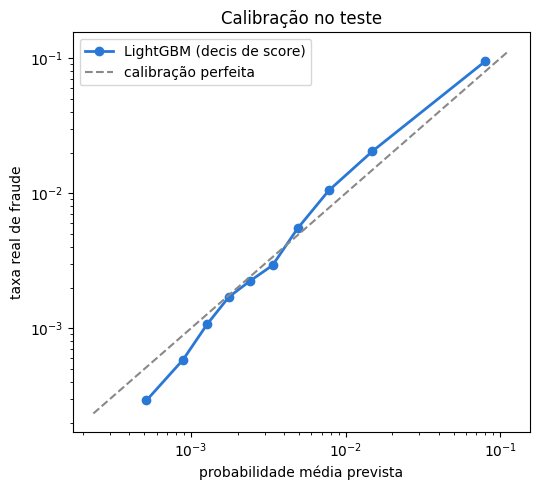

,prob. média prevista,taxa real de fraude
decil de score,,
1,0.05%,0.03%
2,0.09%,0.06%
3,0.13%,0.11%
4,0.18%,0.17%
5,0.24%,0.22%
6,0.34%,0.29%
7,0.49%,0.55%
8,0.78%,1.05%
9,1.49%,2.05%


In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss

s_final = scores_teste["LightGBM (modelo final)"]
y_treino = treino[ALVO].to_numpy()

decil = pd.qcut(s_final, 10, labels=False) + 1
calibracao = pd.DataFrame({"prob. média prevista": s_final, "taxa real de fraude": y_teste}).groupby(decil).mean()
calibracao.index.name = "decil de score"

brier_modelo = brier_score_loss(y_teste, s_final)
brier_constante = brier_score_loss(y_teste, np.full(len(y_teste), y_treino.mean()))
print(f"Probabilidade média prevista: {s_final.mean():.2%} | taxa real no teste: {y_teste.mean():.2%}")
print(f"Brier: modelo {brier_modelo:.5f} vs. constante {brier_constante:.5f} "
      f"(redução de {1 - brier_modelo / brier_constante:.1%})")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(calibracao["prob. média prevista"], calibracao["taxa real de fraude"],
        marker="o", lw=2, color="#2a78d6", label="LightGBM (decis de score)")
limites = [calibracao.min().min() * 0.8, calibracao.max().max() * 1.2]
ax.plot(limites, limites, ls="--", color="#8a8986", label="calibração perfeita")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("probabilidade média prevista")
ax.set_ylabel("taxa real de fraude")
ax.set_title("Calibração no teste")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "05_calibracao.png", dpi=150, bbox_inches="tight")
plt.show()

calibracao.style.format("{:.2%}")

**Conclusão:**

- **A ordenação é sólida:** a taxa real de fraude cresce de forma monotônica com o score — de 0,03% no 1º decil a 9,5% no 10º —, e as probabilidades seguem a mesma ordem de grandeza da realidade em todas as faixas.
- **A escala está levemente deslocada:** o modelo subestima o risco nos decis mais altos (8º a 10º: prevê 0,8% / 1,5% / 8,0%; reais 1,1% / 2,1% / 9,5%) e, no total, prevê 1,18% contra 1,40% reais.
- **Causa: drift na proporção de fraudes.** A taxa no teste (1,40%) é maior que a do treino (1,03%); o modelo, treinado no passado, não acompanha esse aumento. A troca para `scale_pos_weight = 1` (notebook 04) eliminou a distorção causada pelo treino; a que resta vem da mudança no próprio fenômeno.
- O **Brier score** é 10,5% menor que o de uma previsão constante — ganho modesto, típico de eventos raros, em que o Brier é dominado pela grande maioria de legítimos.
- **Em produção:** como a política recomendada é por orçamento (ranking), a calibração não afeta quem é revisado. Mas, se as probabilidades forem usadas diretamente (ex.: para precificar risco), seria preciso recalibrá-las periodicamente com dados recentes (ex.: regressão isotônica).

## 2. Política de limiar

O recall da seção 1 supõe um limiar que dá exatamente 5% de FPR no teste — algo impossível de escolher de antemão. Comparamos três políticas, todas definidas **sem olhar o teste**:

- **(a) Limiar fixo, calculado no treino:** percentil de 95% dos scores dos legítimos nos próprios dados de treino do modelo final (sujeito ao viés visto no notebook 04).
- **(b) Limiar fixo, calibrado fora do treino:** um modelo idêntico, treinado nos meses 0–4, define o limiar no mês 5 (que não viu) e pontua o teste.
- **(c) Orçamento mensal:** revisar os X% de pedidos mais suspeitos de cada mês, com X escolhido no treino para corresponder a ~5% de FPR: X = 5% × (1 − p) + recall × p, onde p é a taxa de fraude do treino e o recall é o da validação. Imune a deslocamentos nos scores; usa só os scores (nunca os rótulos) do mês.

In [7]:
from src.validacao import FPR_ALVO, limiar_para_fpr, taxas

s_final = scores_teste["LightGBM (modelo final)"]
y_treino = treino[ALVO].to_numpy()

# (a) limiar calculado nos próprios dados de treino do modelo final
limiar_ingenuo = limiar_para_fpr(y_treino, pontuar(modelos["LightGBM (modelo final)"], limpar(treino)))

# (b) modelo idêntico treinado nos meses 0–4; limiar calibrado no mês 5 (fora do treino)
treino_0a4, mes_5 = treino[treino["month"] <= 4], treino[treino["month"] == 5]
modelo_calibrado = criar_modelo_final()
modelo_calibrado.fit(limpar(treino_0a4), treino_0a4[ALVO])
limiar_fora = limiar_para_fpr(mes_5[ALVO].to_numpy(), pontuar(modelo_calibrado, limpar(mes_5)))
s_calibrado = pontuar(modelo_calibrado, X_teste)

# (c) orçamento: fração de pedidos revisados que corresponde a ~5% de FPR no treino
p_treino = y_treino.mean()
RECALL_VALIDACAO = 0.5665
ORCAMENTO = FPR_ALVO * (1 - p_treino) + RECALL_VALIDACAO * p_treino

POLITICAS = {
    "(a) limiar fixo, calculado no treino": (s_final, lambda s: limiar_ingenuo),
    "(b) limiar fixo, calibrado fora do treino": (s_calibrado, lambda s: limiar_fora),
    f"(c) orçamento: {ORCAMENTO:.1%} mais suspeitos do mês": (s_final, lambda s: np.quantile(s, 1 - ORCAMENTO)),
}

linhas = []
for nome, (scores, regra) in POLITICAS.items():
    for mes in [6, 7]:
        m = (teste["month"] == mes).to_numpy()
        limiar = regra(scores[m])
        alerta = scores[m] > limiar
        t = taxas(y_teste[m], scores[m], limiar)
        linhas.append({"política": nome, "mês": mes, "FPR": t["FPR"], "recall": t["recall"],
                       "precisão": y_teste[m][alerta].mean(),
                       "alertas por 10 mil pedidos": 1e4 * alerta.mean()})

politicas = pd.DataFrame(linhas).set_index(["política", "mês"])
politicas.to_csv(RAIZ / "reports" / "politicas_05_limiar.csv", float_format="%.4f")
politicas.style.format({"FPR": "{:.2%}", "recall": "{:.3f}", "precisão": "{:.1%}",
                        "alertas por 10 mil pedidos": "{:.0f}"})

**Conclusão:**

- **(a) Limiar fixo calculado no treino:** FPR de 6,3% e 5,3% — acima do planejado, e variando entre meses.
- **(b) Limiar fixo calibrado fora do treino:** FPR de 6,5% e 5,5% — **não melhorou**. O viés do limiar calculado no próprio treino (notebook 04) existe, mas no teste é pequeno diante do **drift**: os scores dos meses 6–7 estão deslocados em relação a todos os meses anteriores, inclusive o mês 5 usado na calibração. Além disso, esse modelo deixa o mês mais recente fora do treino.
- **(c) Orçamento mensal:** FPR de **4,9% e 4,8%** — a mais próxima dos 5% e a mais estável entre meses —, com volume constante de **553 alertas por 10 mil pedidos** (contra 612 a 722 nas políticas fixas). O recall é um pouco menor (0,524 e 0,571) porque ela incomoda menos clientes legítimos; as políticas fixas ganham recall barrando mais clientes bons, de forma imprevisível.
- **Recomendação:** operar com **orçamento de alertas** — revisar os ~5,5% de pedidos mais suspeitos, com o percentil recalculado numa janela móvel (ex.: últimos 30 dias). Isso dá previsibilidade à equipe de revisão e imunidade a deslocamentos nos scores, mas não protege contra mudanças na **relação** entre variáveis e fraude — daí a necessidade de monitorar o recall e retreinar o modelo periodicamente.

## 3. Justiça por idade no teste

**Pergunta:** com um limiar único (5% de FPR global), legítimos com 50+ anos são barrados com mais frequência? E qual é o custo, em recall, de igualar a FPR entre os grupos com um limiar por grupo?

Os limiares são calculados no próprio teste — o objetivo é medir o tamanho do trade-off, não definir o limiar de produção. Usar a idade explicitamente na decisão é uma escolha com implicações éticas e regulatórias; aqui é só uma análise.

In [8]:
mais_50 = (teste["customer_age"] >= 50).to_numpy()
grupos = {"< 50 anos": ~mais_50, "≥ 50 anos": mais_50}

limiar_unico = limiar_para_fpr(y_teste, s_final)
limiares_por_grupo = {g: limiar_para_fpr(y_teste[m], s_final[m]) for g, m in grupos.items()}

linhas = []
for nome, limiar_de in [("limiar único (5% de FPR global)", lambda g: limiar_unico),
                        ("limiar por grupo (5% de FPR em cada)", lambda g: limiares_por_grupo[g])]:
    alerta = np.zeros(len(y_teste), dtype=bool)
    linha = {"política": nome}
    for g, m in grupos.items():
        alerta[m] = s_final[m] > limiar_de(g)
        linha[f"FPR {g}"] = alerta[m & (y_teste == 0)].mean()
        linha[f"recall {g}"] = alerta[m & (y_teste == 1)].mean()
    linha["razão de FPR"] = (min(linha["FPR < 50 anos"], linha["FPR ≥ 50 anos"])
                             / max(linha["FPR < 50 anos"], linha["FPR ≥ 50 anos"]))
    linha["FPR global"] = alerta[y_teste == 0].mean()
    linha["recall global"] = alerta[y_teste == 1].mean()
    linhas.append(linha)

justica = pd.DataFrame(linhas).set_index("política").T
justica.to_csv(RAIZ / "reports" / "justica_05_idade.csv", float_format="%.4f")
print(f"Pedidos de 50+ anos: {mais_50.mean():.1%} | taxa de fraude: "
      f"{y_teste[~mais_50].mean():.2%} (< 50) vs. {y_teste[mais_50].mean():.2%} (≥ 50)")
justica.style.format("{:.3f}", decimal=",")

Pedidos de 50+ anos: 16.5% | taxa de fraude: 1.10% (< 50) vs. 2.93% (≥ 50)


política,limiar único (5% de FPR global),limiar por grupo (5% de FPR em cada)
FPR < 50 anos,"0,037","0,050"
recall < 50 anos,"0,475","0,529"
FPR ≥ 50 anos,"0,115","0,050"
recall ≥ 50 anos,"0,690","0,502"
razão de FPR,"0,326","1,000"
FPR global,"0,050","0,050"
recall global,"0,549","0,520"


**Conclusão:**

- **Com limiar único**, legítimos com 50+ anos são barrados **3,1× mais** (FPR de 11,5% vs. 3,7%; razão de 0,326, praticamente igual à da validação, ~0,30). A desigualdade é estável e reflete a taxa de fraude 2,7× maior nesse grupo (2,93% vs. 1,10%).
- **Com um limiar por grupo**, a razão de FPR chega a 1,0, e o **recall global cai de 0,549 para 0,520** (-0,029, ~4 fraudes a menos detectadas a cada 10 mil pedidos). O recall do grupo 50+ cai de 0,69 para 0,50; o do grupo < 50 sobe de 0,475 para 0,529.
- **O custo da igualdade (-0,029) é menor que o ganho do LightGBM sobre a regressão logística (+0,039):** o LightGBM com limiar por grupo (0,520) ainda supera a logística sem restrição alguma (0,510). Um modelo melhor "paga" a correção.
- A escolha entre as duas políticas é de **negócio e regulação**, não técnica — usar a idade explicitamente na decisão pode ser questionável ou vedado. O papel da análise é tornar o trade-off visível e quantificado.

## 4. Interpretação: SHAP

O SHAP distribui o score de cada pedido entre as variáveis: a soma das contribuições mais um valor de base é exatamente o score do modelo (escala log-odds; positivo empurra para fraude). Calculado numa amostra de 20 mil pedidos do teste.

**Hipótese do notebook 02:** um modelo não linear daria mais peso a `proposed_credit_limit` e `credit_risk_score`, pouco usados pela regressão logística.

Aditividade conferida: base + soma dos SHAP = score do modelo


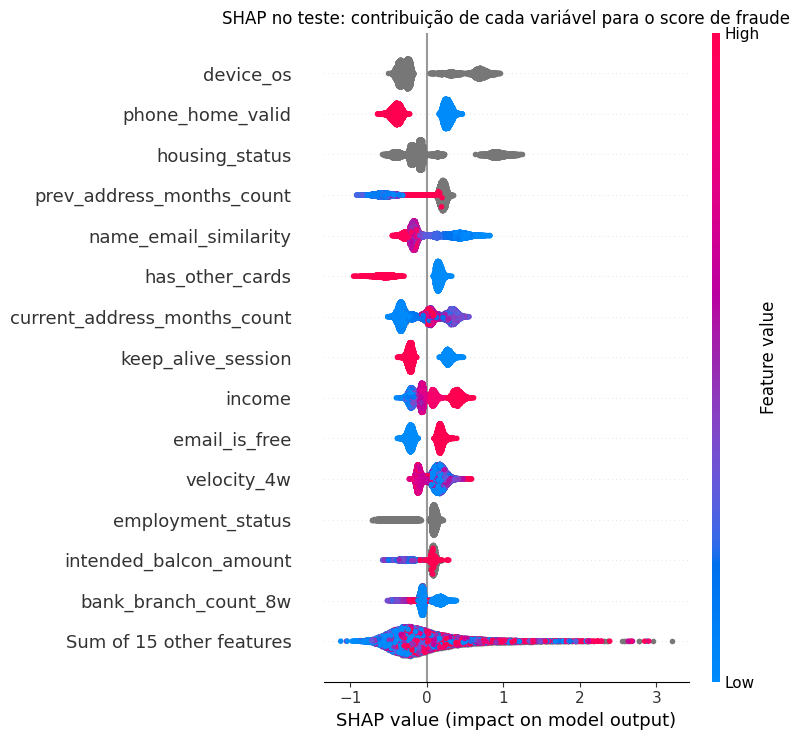

,posição no LightGBM (SHAP),posição na logística (permutação)
device_os,1,2
phone_home_valid,2,3
housing_status,3,1
prev_address_months_count,4,4
name_email_similarity,5,6
has_other_cards,6,5
current_address_months_count,7,22
keep_alive_session,8,7
income,9,10
email_is_free,10,9


In [9]:
import matplotlib.pyplot as plt
import warnings
from tqdm import TqdmWarning
warnings.filterwarnings("ignore", category=TqdmWarning)  # aviso cosmético de barra de progresso
import shap

modelo_final = modelos["LightGBM (modelo final)"]
amostra = teste.sample(20_000, random_state=SEMENTE)
X_amostra = modelo_final["pre"].transform(limpar(amostra))  # mesma entrada que o LightGBM recebe

explicador = shap.TreeExplainer(modelo_final["modelo"])
valores_shap = explicador(X_amostra)

# Checagem: base + soma das contribuições = score bruto do modelo?
score_bruto = modelo_final["modelo"].predict(X_amostra, raw_score=True)
assert np.allclose(valores_shap.values.sum(axis=1) + valores_shap.base_values, score_bruto, atol=1e-4)
print("Aditividade conferida: base + soma dos SHAP = score do modelo")

plt.figure()
shap.plots.beeswarm(valores_shap, max_display=15, show=False)
plt.title("SHAP no teste: contribuição de cada variável para o score de fraude")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

# Comparação com a regressão logística (importância por permutação, notebook 02)
importancia_shap = pd.Series(np.abs(valores_shap.values).mean(axis=0), index=X_amostra.columns)
importancia_logistica = pd.read_csv(RAIZ / "reports" / "importancia_02_logistica.csv", index_col=0)["recall@5%FPR"]
comparacao_importancia = pd.DataFrame({
    "posição no LightGBM (SHAP)": importancia_shap.rank(ascending=False).astype(int),
    "posição na logística (permutação)": importancia_logistica.rank(ascending=False).astype(int),
}).sort_values("posição no LightGBM (SHAP)")
comparacao_importancia.head(12)

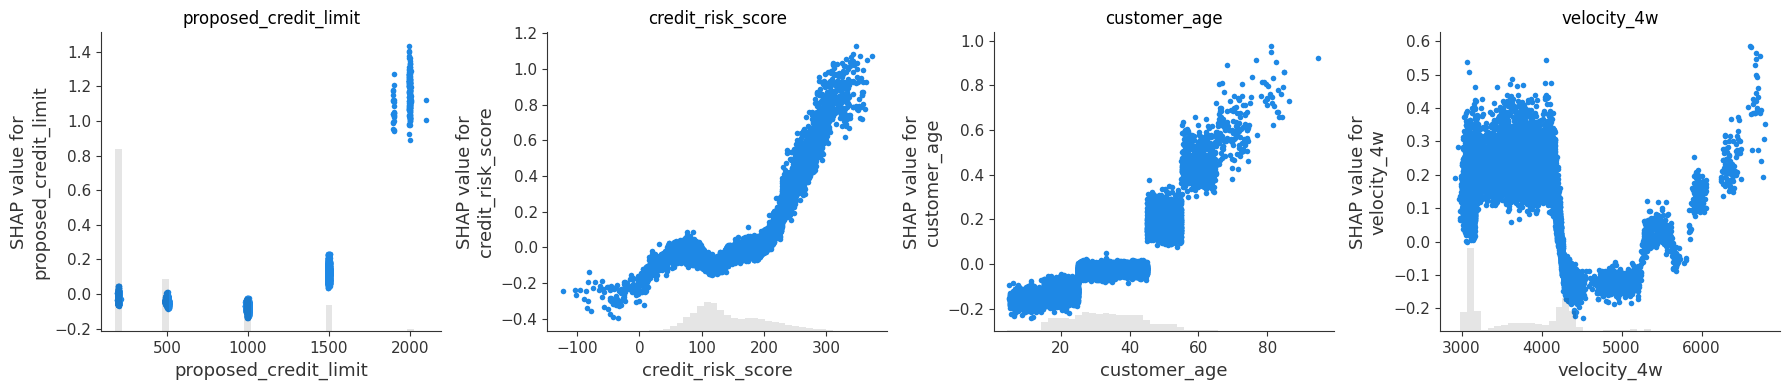

,posição (média |SHAP|),média |SHAP|,"percentil 99,9 |SHAP|"
proposed_credit_limit,22,"0,052","1,278"
credit_risk_score,16,"0,102","1,002"
customer_age,18,"0,088","0,763"
velocity_4w,11,"0,150","0,445"
device_os,1,"0,402","0,890"
housing_status,3,"0,324","1,151"


In [10]:
DESTAQUES = ["proposed_credit_limit", "credit_risk_score", "customer_age", "velocity_4w"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, coluna in zip(axes, DESTAQUES):
    shap.plots.scatter(valores_shap[:, coluna], ax=ax, show=False)
    ax.set_title(coluna)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_shap_dependencia.png", dpi=150, bbox_inches="tight")
plt.show()

# Média vs. casos extremos: sinais raros e fortes têm média baixa, mas cauda alta
abs_shap = np.abs(valores_shap.values)
forca = pd.DataFrame({
    "posição (média |SHAP|)": importancia_shap.rank(ascending=False).astype(int),
    "média |SHAP|": abs_shap.mean(axis=0),
    "percentil 99,9 |SHAP|": np.percentile(abs_shap, 99.9, axis=0),
}, index=X_amostra.columns)
forca.loc[DESTAQUES + ["device_os", "housing_status"]].style.format(precision=3, decimal=",")

**Conclusão:**

- **O topo do ranking coincide com o da regressão logística:** as 6 variáveis mais importantes são as mesmas (`device_os`, `phone_home_valid`, `housing_status`, `prev_address_months_count`, `name_email_similarity`, `has_other_cards`), em outra ordem. Os dois modelos concordam sobre **o que** importa.
- **A hipótese do notebook 02 se confirma, de forma mais sutil que o previsto.** `proposed_credit_limit` é só a 22ª variável pela média do |SHAP|, mas tem a **maior contribuição de todas no percentil 99,9** (1,28): limites de ~2.000 somam +1,0 a +1,4 ao score (chance de fraude ~3× maior), reproduzindo o degrau da EDA. `credit_risk_score` tem a forma de "taco de hóquei" — plano até ~200 e crescendo forte depois. São sinais **raros e fortes**: afetam poucos pedidos, com muito peso. A regressão logística não representava essas formas; **a média do |SHAP| esconde sinais raros**.
- **Variáveis não lineares sobem no ranking:** `current_address_months_count` (22º na logística → 7º) captura o padrão não monotônico da EDA (fraude maior nos valores intermediários).
- **`customer_age`** contribui em degraus por década, com salto a partir dos 50 anos — coerente com a desigualdade da seção 3.
- **Alerta — `velocity_4w` como "relógio disfarçado":** sobe do 26º para o 11º lugar, com uma curva sem sentido de negócio (velocidades baixas → mais fraude). Como a variável caiu ao longo dos meses e os meses recentes tiveram mais fraude, o modelo provavelmente aprendeu um **efeito de tempo**, não um padrão de fraude. No teste, com velocidades ainda menores, isso desloca os scores — uma causa provável da instabilidade do limiar. Pela regra do notebook, o modelo não é alterado; **testar o modelo sem as velocidades é a principal melhoria para uma próxima versão**.

### Exemplo: uma fraude explicada

O SHAP também explica pedidos individuais. Abaixo, a fraude real de maior score na amostra: cada barra mostra quanto uma variável empurrou o score para cima (vermelho) ou para baixo (azul), partindo do valor médio do modelo. É assim que um analista de prevenção a fraude entenderia por que um pedido foi para revisão.

Probabilidade de fraude prevista: 75.1%


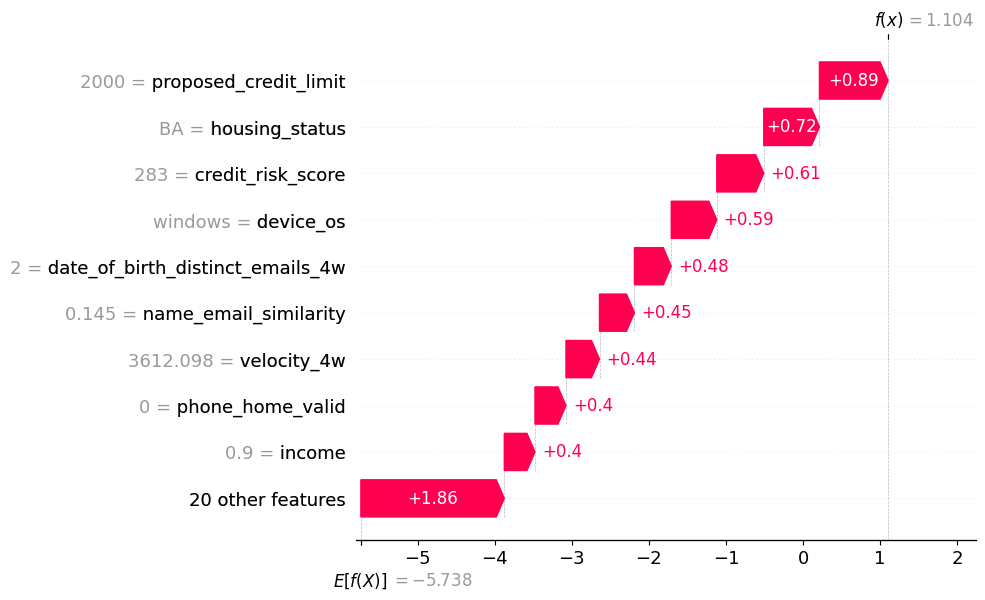

In [11]:
fraudes = np.flatnonzero(amostra[ALVO].to_numpy() == 1)
i = fraudes[np.argmax(valores_shap.values[fraudes].sum(axis=1))]  # fraude real com maior score
print(f"Probabilidade de fraude prevista: {modelo_final['modelo'].predict_proba(X_amostra.iloc[[i]])[:, 1][0]:.1%}")

plt.figure()
shap.plots.waterfall(valores_shap[i], max_display=10, show=False)
plt.savefig(FIG_DIR / "05_shap_exemplo_fraude.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura:** o pedido parte do valor médio do modelo (−5,74 em log-odds, ≈ 0,3% de chance de fraude) e chega a +1,10 (**75,1%**). Nenhuma variável decide sozinha: são vários sinais de alerta da EDA se acumulando — limite proposto de 2.000 (+0,89, o "sinal raro e forte" da seção 4), `housing_status = BA` (+0,72), score de crédito alto (+0,61), `device_os = windows` (+0,59), e-mail pouco parecido com o nome (+0,45), telefone fixo inválido (+0,40). O modelo não aplica uma regra de fraude; soma pequenas evidências. Note também `velocity_4w` (+0,44): parte da suspeita vem do período em que o pedido chegou, não do cliente — o efeito de "relógio disfarçado" discutido acima, visível num caso concreto. É esse tipo de explicação que permite a um analista revisar e contestar a decisão do modelo.

## 5. Modelo salvo

O pipeline completo (pré-processamento + LightGBM) é salvo em `models/lightgbm_final.joblib`, com uma ficha técnica em `models/metadados.json`. Novos pedidos são pontuados com `python -m src.prever entrada.csv saida.csv`, que aplica a política de orçamento da seção 2.

In [12]:
import json
import joblib
import lightgbm
import sklearn

MODELS_DIR = RAIZ / "models"
joblib.dump(modelo_final, MODELS_DIR / "lightgbm_final.joblib")

metricas_teste = avaliar(y_teste, s_final)
metadados = {
    "modelo": "LightGBM — candidato #11 da busca aleatória (notebook 04), com scale_pos_weight = 1",
    "hiperparametros": PARAMS_FINAIS,
    "undersampling": UNDERSAMPLING,
    "treino": {"meses": [0, 5], "linhas": int(len(treino)), "taxa_fraude": float(y_treino.mean())},
    "validacao_temporal_3_folds": {"recall_5fpr": 0.5665, "pr_auc": 0.1779, "roc_auc": 0.9081},
    "teste": {"meses": [6, 7], **{k: float(v) for k, v in metricas_teste.items()}},
    "politica_limiar": {"tipo": "orçamento: revisar a fração mais suspeita de cada lote",
                        "orcamento": float(ORCAMENTO)},
    "versoes": {"python": sys.version.split()[0], "scikit-learn": sklearn.__version__,
                "lightgbm": lightgbm.__version__, "pandas": pd.__version__},
}
(MODELS_DIR / "metadados.json").write_text(json.dumps(metadados, indent=2, ensure_ascii=False), encoding="utf-8")

# Conferência: o modelo recarregado do disco dá os mesmos scores?
recarregado = joblib.load(MODELS_DIR / "lightgbm_final.joblib")
assert np.allclose(pontuar(recarregado, X_teste.head(1000)), s_final[:1000])
print("Modelo salvo e conferido.")
print(json.dumps(metadados, indent=2, ensure_ascii=False))

Modelo salvo e conferido.
{
  "modelo": "LightGBM — candidato #11 da busca aleatória (notebook 04), com scale_pos_weight = 1",
  "hiperparametros": {
    "colsample_bytree": 0.5070399113575422,
    "learning_rate": 0.018142616985100158,
    "min_child_samples": 100,
    "n_estimators": 518,
    "num_leaves": 47,
    "reg_lambda": 0.2653627132902634,
    "scale_pos_weight": 1,
    "subsample": 0.6792328642721364
  },
  "undersampling": false,
  "treino": {
    "meses": [
      0,
      5
    ],
    "linhas": 794989,
    "taxa_fraude": 0.010252972053701372
  },
  "validacao_temporal_3_folds": {
    "recall_5fpr": 0.5665,
    "pr_auc": 0.1779,
    "roc_auc": 0.9081
  },
  "teste": {
    "meses": [
      6,
      7
    ],
    "recall@5%FPR": 0.5489923558026407,
    "PR-AUC": 0.19638281270615263,
    "ROC AUC": 0.8955184273139063
  },
  "politica_limiar": {
    "tipo": "orçamento: revisar a fração mais suspeita de cada lote",
    "orcamento": 0.05529566006573677
  },
  "versoes": {
    "pyt

In [13]:
from src.prever import carregar, prever

modelo_salvo, meta = carregar()
lote = teste.head(5_000)
saida_lote = prever(lote, modelo_salvo, meta["politica_limiar"]["orcamento"])
print(f"Lote de {len(lote):,}: {saida_lote['revisar'].mean():.2%} marcados para revisão "
      f"(orçamento: {meta['politica_limiar']['orcamento']:.2%})")

# Robustez: pontuar pedido por pedido dá o mesmo resultado que pontuar o lote inteiro?
# (cada pedido isolado tem só uma categoria por coluna; o LightGBM reconcilia com as categorias do treino)
individual = np.array([prever(lote.iloc[[k]], modelo_salvo, limiar=0.5)["prob_fraude"].iloc[0] for k in range(200)])
assert np.allclose(individual, saida_lote["prob_fraude"].to_numpy()[:200])
print("Pedidos individuais pontuados igual ao lote: ok")

Lote de 5,000: 5.54% marcados para revisão (orçamento: 5.53%)
Pedidos individuais pontuados igual ao lote: ok


## 6. Resumo

| | Recall a 5% FPR | PR-AUC | ROC AUC |
|---|---|---|---|
| **LightGBM — validação** (3 folds temporais) | 0,566 | 0,178 | 0,908 |
| **LightGBM — teste** (meses 6–7) | **0,549** | **0,196** | **0,896** |
| Regressão logística — teste (régua) | 0,510 | 0,168 | 0,884 |

- **O modelo generaliza:** no teste, o recall cai apenas 0,018 em relação à validação, e a vantagem sobre a régua cresce (+0,039). As três previsões registradas antes de abrir o teste se confirmaram.
- **Operação:** limiares fixos erram a FPR por causa do drift (6,3% e 5,3% no teste), e calibrar o limiar fora do treino não resolveu. A política de **orçamento de alertas** (revisar os ~5,5% de pedidos mais suspeitos) manteve a FPR em 4,9% e 4,8%, com volume constante de revisão — é a política recomendada.
- **Justiça:** com limiar único, legítimos com 50+ anos são barrados 3,1× mais (razão de FPR de 0,33). Igualar a FPR com um limiar por grupo custa 0,029 de recall — menos que o ganho do modelo sobre a régua. A escolha é de negócio e regulação.
- **Interpretação:** o modelo concorda com a regressão logística sobre as variáveis mais importantes e, além delas, captura sinais raros e fortes (limite proposto de ~2.000, score de crédito alto) que a logística não representava. **Ponto de atenção:** `velocity_4w` parece funcionar como um indicador de tempo, não de fraude.
- **Próximas melhorias:** (1) retreinar sem as variáveis de velocidade e comparar a estabilidade; (2) monitorar a taxa de fraude e o recall em produção, retreinando periodicamente; (3) avaliar técnicas de justiça algorítmica além do limiar por grupo.
- Modelo em `models/lightgbm_final.joblib`, ficha técnica em `models/metadados.json`, inferência com `python -m src.prever`.